In [1]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import make_scorer, f1_score, recall_score
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

df = pd.read_csv("../data/raw/student-mat.csv", sep=";")
df["pass"] = (df["G3"] >= 10).astype(int)
y = df["pass"]

X_all = df.drop(columns=["G3", "pass"])
X_no_grades = df.drop(columns=["G1", "G2", "G3", "pass"])

In [2]:
def make_preprocessor(X):
    cat_cols = X.select_dtypes(include="object").columns.tolist()
    num_cols = X.select_dtypes(exclude="object").columns.tolist()
    return ColumnTransformer([
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ])

models = {
    "Dummy (baseline)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42),
    "SVM": SVC(class_weight="balanced", random_state=42),
    "k-NN": KNeighborsClassifier(n_neighbors=7),
    "XGBoost": XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.05,
                             eval_metric="logloss", random_state=42),
    "LightGBM": LGBMClassifier(n_estimators=200, max_depth=3, learning_rate=0.05,
                               class_weight="balanced", random_state=42, verbose=-1),
}

# "fail" is class 0, so we score it explicitly
scoring = {
    "accuracy": "accuracy",
    "f1_fail": make_scorer(f1_score, pos_label=0),
    "recall_fail": make_scorer(recall_score, pos_label=0),
    "roc_auc": "roc_auc",
}

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)

In [3]:
def run_all(X, label):
    rows = []
    for name, clf in models.items():
        pipe = Pipeline([("prep", make_preprocessor(X)), ("clf", clf)])
        res = cross_validate(pipe, X, y, cv=cv, scoring=scoring, n_jobs=-1)
        rows.append({
            "Features": label,
            "Model": name,
            "Accuracy": res["test_accuracy"].mean(),
            "F1 (fail)": res["test_f1_fail"].mean(),
            "Recall (fail)": res["test_recall_fail"].mean(),
            "ROC-AUC": res["test_roc_auc"].mean(),
            "ROC-AUC std": res["test_roc_auc"].std(),
        })
    return pd.DataFrame(rows)

results = pd.concat([
    run_all(X_all, "A: with G1, G2"),
    run_all(X_no_grades, "B: without G1, G2"),
], ignore_index=True)

results = results.round(3)
results.to_csv("../reports/model_comparison.csv", index=False)

In [4]:
for label in results["Features"].unique():
    print(f"\n=== {label} ===")
    print(results[results["Features"] == label]
          .drop(columns="Features")
          .sort_values("ROC-AUC", ascending=False)
          .to_string(index=False))


=== A: with G1, G2 ===
              Model  Accuracy  F1 (fail)  Recall (fail)  ROC-AUC  ROC-AUC std
Logistic Regression     0.916      0.881          0.931    0.975        0.011
            XGBoost     0.900      0.849          0.859    0.973        0.011
           LightGBM     0.905      0.861          0.895    0.970        0.012
      Random Forest     0.911      0.871          0.921    0.970        0.011
                SVM     0.873      0.822          0.892    0.956        0.016
      Decision Tree     0.893      0.842          0.879    0.906        0.042
               k-NN     0.814      0.664          0.569    0.891        0.022
   Dummy (baseline)     0.671      0.000          0.000    0.500        0.000

=== B: without G1, G2 ===
              Model  Accuracy  F1 (fail)  Recall (fail)  ROC-AUC  ROC-AUC std
      Random Forest     0.685      0.476          0.436    0.688        0.048
           LightGBM     0.654      0.489          0.505    0.678        0.070
Logistic Regr

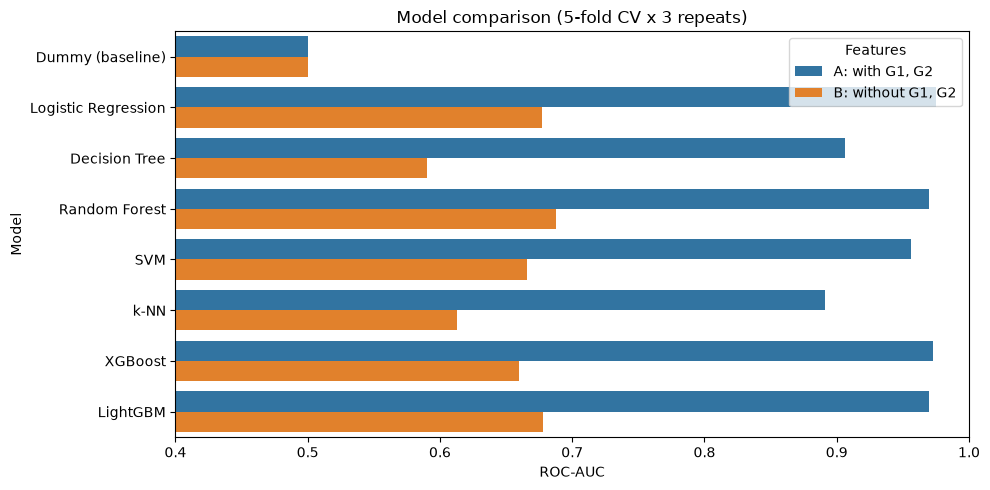

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))
sns.barplot(data=results, x="ROC-AUC", y="Model", hue="Features")
plt.title("Model comparison (5-fold CV x 3 repeats)")
plt.xlim(0.4, 1.0)
plt.tight_layout()
plt.savefig("../reports/model_comparison.png", dpi=200)
plt.show()